# 1. Feature Engineering (v2)
**CRISP-DM stage:** Data Preparation.


In [31]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeClassifier
import textwrap
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import recall_score, precision_score


def story_title(text, size=12, **kw):
    width = int(plt.gcf().get_figwidth() * 7.2)                 
    plt.title(textwrap.fill(text, width), fontsize=size, weight="bold", **kw)
    

sns.set_theme(style="whitegrid")
RED, GREEN, BLUE, AMBER = "#B23B32", "#3F8B5D", "#3D5A99", "#B9821E"   
FIG_DIR = "../outputs/figures"      
df = pd.read_csv("../data/processed/smart_waste_dataset_cleaned.csv", parse_dates=["ArrivalDate", "ExpiryDate"])
df["RowID"] = df.index          
print("Shape:", df.shape)
df.head(3)

Shape: (1000, 22)


,ItemName,Brand,Category,StockQty,ArrivalDate,ExpiryDate,DaysUntilExpiry,DailySaleAvg,SpoilageChance,SuggestedAction,...,OnPromotion,TemperatureSensitive,StoreID,Zone,TemperatureSupport,DistanceToNearestStore,AvgDailySaleInNearbyStores,Zone_Missing,TemperatureSupport_Missing,RowID
0,Bingo Mad Angles,ITC,Snacks,92,2025-06-20,2025-06-28,0.5,12.1,1.0,donate,...,False,False,Chennai_0,Unknown,Unknown,6.1,13.178196,1,1,0
1,Multigrain Cookies,Sunfeast,Bakery,224,2025-06-18,2025-06-29,1.0,9.0,1.0,donate,...,False,False,Kanpur_0,Unknown,Unknown,5.0,8.981118,1,1,1
2,Nestlé Yogurt 150g,Nestlé,Dairy,201,2025-06-23,2025-06-26,0.5,20.1,1.0,donate,...,True,True,Mumbai_0,West,No,10.3,17.169273,0,0,2


#### Step 1: Drop the leaks 
A column that already contains the answer, or was computed from it. 

| Column | Why it leaks |
|---|---|
| `SpoilageChance` | Equals 1.0 for every spoiled item. It was derived from the outcome. |
| `SuggestedAction` | Says "donate" for every spoiled item. It is a label built from the outcome. |
| `DaysUntilExpiry` | The label was built around expiry timing: a handful of values reproduce the outcome almost exactly



In [32]:
# Evidence 1: SpoilageChance and SuggestedAction versus the target
print(df.groupby("IsSpoiled")["SpoilageChance"].describe()[["min", "mean", "max"]])
print()
print(pd.crosstab(df["IsSpoiled"], df["SuggestedAction"]))

            min      mean  max
IsSpoiled                     
False      0.08  0.673541  1.0
True       1.00  1.000000  1.0

SuggestedAction  discount  donate  monitor  none
IsSpoiled                                       
False                  23     243       96   200
True                    0     438        0     0


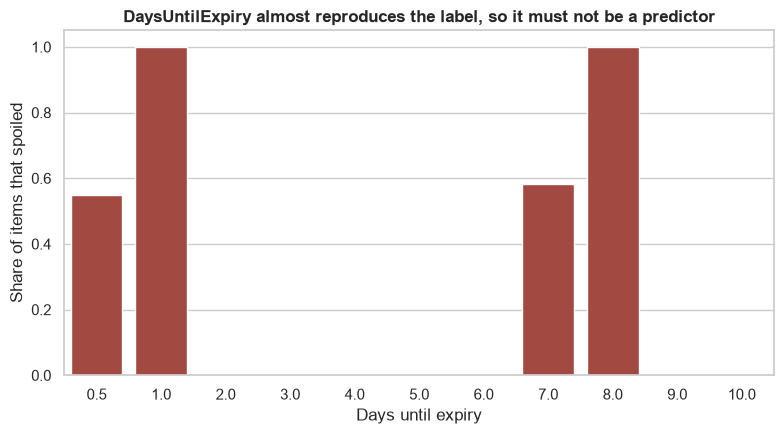

In [33]:
# Evidence 2: share of items that spoiled at each DaysUntilExpiry value.
rate = df.groupby("DaysUntilExpiry")["IsSpoiled"].mean().reset_index()
plt.figure(figsize=(8, 4.5))
sns.barplot(data=rate, x="DaysUntilExpiry", y="IsSpoiled", color=RED)
plt.title("DaysUntilExpiry almost reproduces the label, so it must not be a predictor", fontsize=12, weight="bold")
plt.xlabel("Days until expiry"); plt.ylabel("Share of items that spoiled")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fe_leak_daysuntilexpiry.png", dpi=150)   # BREAKS IF: savefig comes after plt.show()
plt.show()

In [34]:
df[["RowID", "DaysUntilExpiry"]].to_csv("../data/interim/display_lookup_v2.csv", index=False)

leaks = ["DaysUntilExpiry", "SpoilageChance", "SuggestedAction"]
df = df.drop(columns=leaks)

df["ArrivalDate"] = pd.to_datetime(df["ArrivalDate"])
df["ExpiryDate"] = pd.to_datetime(df["ExpiryDate"])
print("Dropped:", leaks)
print("Date columns:", df[["ArrivalDate", "ExpiryDate"]].dtypes.to_dict())

Dropped: ['DaysUntilExpiry', 'SpoilageChance', 'SuggestedAction']
Date columns: {'ArrivalDate': dtype('<M8[us]'), 'ExpiryDate': dtype('<M8[us]')}


#### Creating safe features
These use only stock, sales and dates, all known when the batch arrives.



In [35]:
df["Total_Shelf_Life_Days"] = (df["ExpiryDate"] - df["ArrivalDate"]).dt.days

df["Stock_Coverage_Ratio"] = df["StockQty"] / df["DailySaleAvg"].replace(0, np.nan)
df["Stock_Coverage_Ratio"] = df["Stock_Coverage_Ratio"].fillna(df["Stock_Coverage_Ratio"].max())

df["Sales_vs_Nearby_Gap"] = df["DailySaleAvg"] - df["AvgDailySaleInNearbyStores"]

df["BatchID"] = (df["ItemName"] + "|" + df["StockQty"].astype(str) + "|" +
                 df["ArrivalDate"].dt.strftime("%m%d") + "|" + df["ExpiryDate"].dt.strftime("%m%d"))
print("Rows:", len(df), "| unique batches:", df["BatchID"].nunique())
print("Batches whose rows disagree on IsSpoiled:", (df.groupby("BatchID")["IsSpoiled"].nunique() > 1).sum())

Rows: 1000 | unique batches: 50
Batches whose rows disagree on IsSpoiled: 0


In [36]:
#Safety checks
raw = pd.read_csv("../data/processed/smart_waste_dataset_cleaned.csv")
y, groups = df["IsSpoiled"], df["BatchID"]

def audit(values, label):
    X = pd.DataFrame({"x": values})
    cv = StratifiedGroupKFold(5, shuffle=True, random_state=1)      # folds never split a batch
    pred = cross_val_predict(DecisionTreeClassifier(max_depth=4, random_state=0), X, y, cv=cv, groups=groups)
    return {"Feature alone": label, "Recall": round(recall_score(y, pred), 2), "Precision": round(precision_score(y, pred), 2)}

audit_table = pd.DataFrame([
    audit(raw["DaysUntilExpiry"].values, "DaysUntilExpiry (the leak, for reference)"),
    audit(df["Total_Shelf_Life_Days"].values, "Total_Shelf_Life_Days"),
    audit(df["Stock_Coverage_Ratio"].values, "Stock_Coverage_Ratio"),
    audit(df["Sales_vs_Nearby_Gap"].values, "Sales_vs_Nearby_Gap"),
])
print(audit_table)
print()
print("Spoiled rate overall (what 'flag everything' scores as precision):", round(y.mean(), 2))

                               Feature alone  Recall  Precision
0  DaysUntilExpiry (the leak, for reference)    0.95       0.57
1                      Total_Shelf_Life_Days    0.42       0.51
2                       Stock_Coverage_Ratio    0.46       0.37
3                        Sales_vs_Nearby_Gap    0.33       0.52

Spoiled rate overall (what 'flag everything' scores as precision): 0.44


In [37]:
# PROOF of the collection date: compare the raw DaysUntilExpiry with (ExpiryDate - 28 June).
AS_OF = pd.Timestamp("2025-06-28")
lookup = pd.read_csv("../data/interim/display_lookup_v2.csv")      # RowID + the original DaysUntilExpiry (saved before the leak was dropped)
proof = df[["RowID", "ExpiryDate"]].merge(lookup, on="RowID")
proof["days_after_collection"] = (proof["ExpiryDate"] - AS_OF).dt.days
proof["expected"] = proof["days_after_collection"].clip(lower=0.5)  # already expired -> floor of 0.5
print("Rows where DaysUntilExpiry matches (ExpiryDate - 28 June), floored at 0.5:", int((proof["expected"] == proof["DaysUntilExpiry"]).sum()), "of", len(proof))

Rows where DaysUntilExpiry matches (ExpiryDate - 28 June), floored at 0.5: 1000 of 1000


In [38]:
# THE FILTER: keep batches that expired BEFORE the collection date. Their outcome is known.
batch_table = (df.groupby("BatchID")
               .agg(ItemName=("ItemName", "first"), Category=("Category", "first"), Arrival=("ArrivalDate", "min"),
                    Expiry=("ExpiryDate", "first"), Rows=("IsSpoiled", "size"), Spoiled=("IsSpoiled", "first"))
               .reset_index())
batch_table["Expired_before_collection"] = batch_table["Expiry"] < AS_OF
batch_table["Spoiled_flag"] = batch_table["Spoiled"].map({True: 1, False: 0, 1: 1, 0: 0})

kept = batch_table[batch_table["Expired_before_collection"]]
dropped = batch_table[~batch_table["Expired_before_collection"]]
print(f"Batches: {len(batch_table)} total | {len(kept)} kept (expired before 28 June) | {len(dropped)} excluded (label not yet known)")
print(f"Of the {len(dropped)} excluded batches, {int(dropped['Spoiled_flag'].sum())} are labelled spoiled before their expiry date, which cannot be verified")
print(f"Kept batches: {int(kept['Spoiled_flag'].sum())} spoiled, {int((1 - kept['Spoiled_flag']).sum())} not spoiled")

dropped.to_csv("../data/interim/excluded_batches_v2.csv", index=False)     # keep a record for the report
df = df[df["BatchID"].isin(kept["BatchID"])].copy()                       # from here on, only batches with a known outcome
print("Rows kept:", len(df))

Batches: 50 total | 28 kept (expired before 28 June) | 22 excluded (label not yet known)
Of the 22 excluded batches, 5 are labelled spoiled before their expiry date, which cannot be verified
Kept batches: 17 spoiled, 11 not spoiled
Rows kept: 572


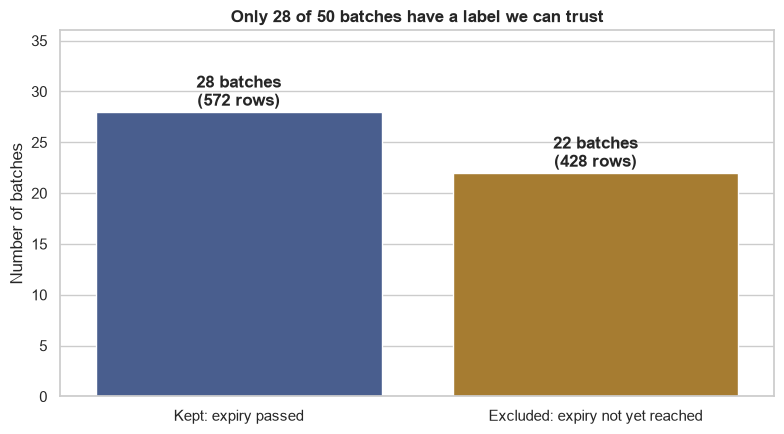

In [ ]:
# VISUAL: how much data the rule removes (counts shown)
summary_counts = pd.DataFrame({"Group": ["Kept: expiry passed", "Excluded: expiry not yet reached"],
                               "Batches": [len(kept), len(dropped)], "Rows": [int(kept["Rows"].sum()), int(dropped["Rows"].sum())]})
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=summary_counts, x="Group", y="Batches", hue="Group", palette=[BLUE, AMBER], legend=False)
for i, r in summary_counts.iterrows(): ax.text(i, r["Batches"] + 0.6, f"{int(r['Batches'])} batches\n({int(r['Rows'])} rows)", ha="center", fontweight="bold")

+plt.ylim(0, summary_counts["Batches"].max() + 8); plt.xlabel(""); plt.ylabel("Number of batches")
story_title(f"Only {len(kept)} of {len(batch_table)} batches have a label we can trust", size=12)
plt.tight_layout(); 
plt.savefig(f"{FIG_DIR}/fe_batches_kept.png", dpi=150); plt.show()

### Convert flags to integers (0/1)


In [40]:
def to_int(series):
    mapped = series.map({True: 1, False: 0, "True": 1, "False": 0, "Yes": 1, "No": 0})
    assert mapped.notna().all(), f"Unexpected value in {series.name}"       
    return mapped.astype(int)

for col in ["IsSpoiled", "OnPromotion", "TemperatureSensitive", "Zone_Missing", "TemperatureSupport_Missing"]:
    df[col] = to_int(df[col])
print(df[["IsSpoiled", "OnPromotion", "TemperatureSensitive", "Zone_Missing", "TemperatureSupport_Missing"]].dtypes)

IsSpoiled                     int64
OnPromotion                   int64
TemperatureSensitive          int64
Zone_Missing                  int64
TemperatureSupport_Missing    int64
dtype: object


In [41]:
assert df.isna().sum().sum() == 0, "Missing values found"
assert not any(c in df.columns for c in ["DaysUntilExpiry", "SpoilageChance", "SuggestedAction"]), "A leak is still present"
df.to_csv("../data/interim/smart_waste_features_v2.csv", index=False)
print("Saved", df.shape, "-> ../data/interim/smart_waste_features_v2.csv")
df.head(3)

Saved (572, 23) -> ../data/interim/smart_waste_features_v2.csv


,ItemName,Brand,Category,StockQty,ArrivalDate,ExpiryDate,DailySaleAvg,StoreLocation,IsSpoiled,OnPromotion,...,TemperatureSupport,DistanceToNearestStore,AvgDailySaleInNearbyStores,Zone_Missing,TemperatureSupport_Missing,RowID,Total_Shelf_Life_Days,Stock_Coverage_Ratio,Sales_vs_Nearby_Gap,BatchID
2,Nestlé Yogurt 150g,Nestlé,Dairy,201,2025-06-23,2025-06-26,20.1,Mumbai,0,1,...,No,10.3,17.169273,0,0,2,3,10.000000,2.930727,Nestlé Yogurt 150g|201|0623|0626
3,Tomato 1kg,Local Farmer,Produce,204,2025-06-18,2025-06-21,9.7,Kanpur,0,1,...,Unknown,8.8,11.075997,1,1,3,3,21.030928,-1.375997,Tomato 1kg|204|0618|0621
4,Banana 6pcs,Local Farmer,Produce,154,2025-06-14,2025-06-21,5.6,Mumbai,1,1,...,No,10.4,4.641460,0,0,4,7,27.500000,0.958540,Banana 6pcs|154|0614|0621
